In [37]:
import numpy as np

import ngsolve 
from ngsolve.webgui import Draw
import netgen.geom2d

import math
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import importlib
import copy # for copying objects (like meshes!)
%matplotlib inline

import cgle  # many subroutines moved here 

notebookroot = 'CGLE_circ_v00_'  # for output files

# some more globals

# for figures
labelpos = [0.02,0.98] 
figsize=(7,3.5)  
cbar_shrink = 0.45
figparms = ['',labelpos,figsize,cbar_shrink]

dt = 0.04  # timestep
korder=3  # order for fes
bndlist0 = 'circ1'  # list of boundaries for Dirichlet bc


In [2]:
importlib.reload(cgle)  # if you are working on the helper routines 

<module 'cgle' from '/Users/aquillen/Desktop/summer25/pylab/CGLE_defect_train/cgle.py'>

### The complex Ginzburg-Landau model dirichlet BC on annular domains

('circ1', 'circ1', 'circ1', 'circ1', 'circ2', 'circ2', 'circ2', 'circ2')


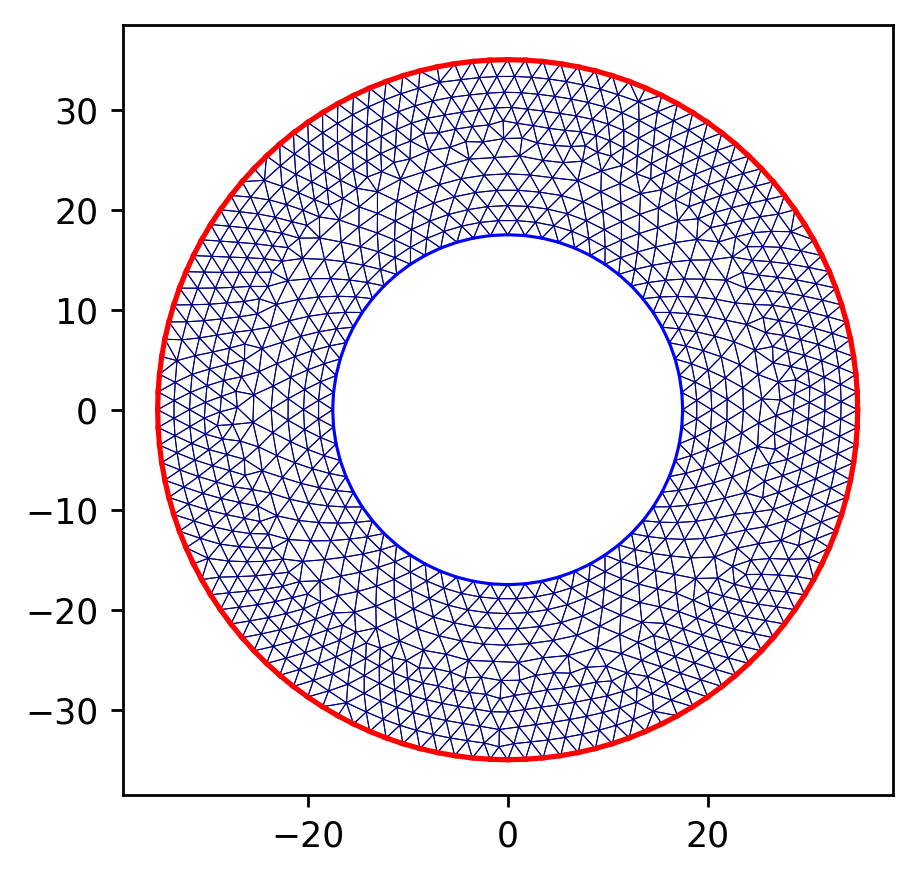

In [40]:
# create domain
geo = netgen.geom2d.CSG2d()

fac = 0.7
rad1 = 50.  #outer
rad2 = rad1/2 # inner
circ1 = netgen.geom2d.Circle( center=(0,0), radius=rad1*fac,  bc="circ1" ,mat="mat1")
circ2 = netgen.geom2d.Circle( center=(0,0), radius=rad2*fac,  bc="circ2" )

geo.Add(circ1-circ2)  # I can't get an a maxh on the circle

maxhval = 2.5*fac
mesh = ngsolve.Mesh(geo.GenerateMesh(maxh=maxhval))
print(mesh.GetBoundaries())

cgle.draw_mesh(mesh,d_boundaries = 'circ1', n_boundaries='circ2',ofile = notebookroot + 'mesh.png',figsize=(4,4))

In [12]:
#It is possible to set individual coefficient functions on different boundaries
#See  https://docu.ngsolve.org/latest/i-tutorials/unit-1.5-subdomains/subdomains.html#Extra-exercises-to-try-out

# routine to set Dirichlet boundaries,  boundary name is hard set
def mkbnd(fes,mesh,amp1=2.9,m=4,itimes=1):

    #amp1 = 2.9
    gfu_bnd = ngsolve.GridFunction(fes) 
    phi = ngsolve.atan2(ngsolve.y,ngsolve.x)
    #m=4
    cphi = ngsolve.cos(m*phi)   #Amp1 e^i mphi set on boundary 
    sphi = ngsolve.sin(m*phi)

    #ramp = ngsolve.fmod(m*phi,2*np.pi)
    bdry_values_real = {'circ1': amp1*cphi} 
    bdry_values_imag = {'circ1': itimes*amp1*sphi}

    cf_real  = mesh.BoundaryCF(bdry_values_real, default=0)
    cf_imag  = mesh.BoundaryCF(bdry_values_imag, default=0)
    
    gfu_bnd.components[0].Set(cf_real,definedon=mesh.Boundaries('circ1')) 
    gfu_bnd.components[1].Set(cf_imag,definedon=mesh.Boundaries('circ1')) 
    return gfu_bnd



In [38]:
fes = cgle.mkfes(mesh,korder,bndlist0) # make finite element system, with Dirichlet boundary 
gfu = ngsolve.GridFunction(fes) # make the field to hold the solution 
gfu_bnd = mkbnd(fes,mesh,amp1=2.5,m=7)

sig = 0.01
cgle.gen_init(gfu,mesh,0,sig,maxhval,A_r0=0.1,A_i0=0)  # generate interior initial conditions gen_init(gfu,mesh,nseeds,sig,hseeds):
# the A_r0, A_i0 are the mean initial field value 

cgle.set_on_boundary(gfu,gfu_bnd,fes) # update all dirichlet boundaries on gfu using gfu_bnd
scene=Draw(cgle.norm_gfu(gfu),mesh, min=0,max=1.2,\
           settings = {  "Colormap" : { "ncolors" : 20 } , "Objects" : {"Wireframe" : False}})

time = 0

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Colormap': {'ncolors': 20}, …

In [39]:

alpha = 2.5; beta = 0.05 # choose a nice pattern Aranson form for parameters
clabel = r'$\alpha=${:.1f}, '.format(alpha) + r'$\beta=${:.1f}'.format(beta) 
figparms[0] = clabel
cgle.Aranson_to_Chate(alpha,beta)
invastar, a_lap, b_op, minv  = cgle.mk_ops(fes,alpha,dt)  # construct operators 
ofileroot = notebookroot+'_a1_'

time = cgle.TimeStepping_CN(fes,gfu,scene,invastar, a_lap,minv,beta, dt, t0=time,tdur=200,nsamples = 200,gfun_op = True,uform='Aran',\
                    poutput=True,ofileroot=ofileroot,figparms=figparms)

# 4 rotating blobs, slight changes in morphology due to phase variations on boundary

 b_1=-2.50 b_3 =20.00
craete bilinearformapplication
 1.000  CGLE_circ_v00__a1_000.png
 2.040  CGLE_circ_v00__a1_001.png
 3.080  CGLE_circ_v00__a1_002.png
 4.120  CGLE_circ_v00__a1_003.png
 5.160  CGLE_circ_v00__a1_004.png
 6.200  CGLE_circ_v00__a1_005.png
 7.240  CGLE_circ_v00__a1_006.png
 8.280  CGLE_circ_v00__a1_007.png
 9.320  CGLE_circ_v00__a1_008.png
 10.360  CGLE_circ_v00__a1_009.png
 11.400  CGLE_circ_v00__a1_010.png
 12.440  CGLE_circ_v00__a1_011.png
 13.480  CGLE_circ_v00__a1_012.png
 14.520  CGLE_circ_v00__a1_013.png
 15.560  CGLE_circ_v00__a1_014.png
 16.600  CGLE_circ_v00__a1_015.png
 17.640  CGLE_circ_v00__a1_016.png
 18.680  CGLE_circ_v00__a1_017.png
 19.720  CGLE_circ_v00__a1_018.png
 20.760  CGLE_circ_v00__a1_019.png
 21.800  CGLE_circ_v00__a1_020.png
 22.840  CGLE_circ_v00__a1_021.png
 23.880  CGLE_circ_v00__a1_022.png
 24.920  CGLE_circ_v00__a1_023.png
 25.960  CGLE_circ_v00__a1_024.png
 27.000  CGLE_circ_v00__a1_025.png
 28.040  CGLE_circ_v00__a1_026.png
 29.080  CG

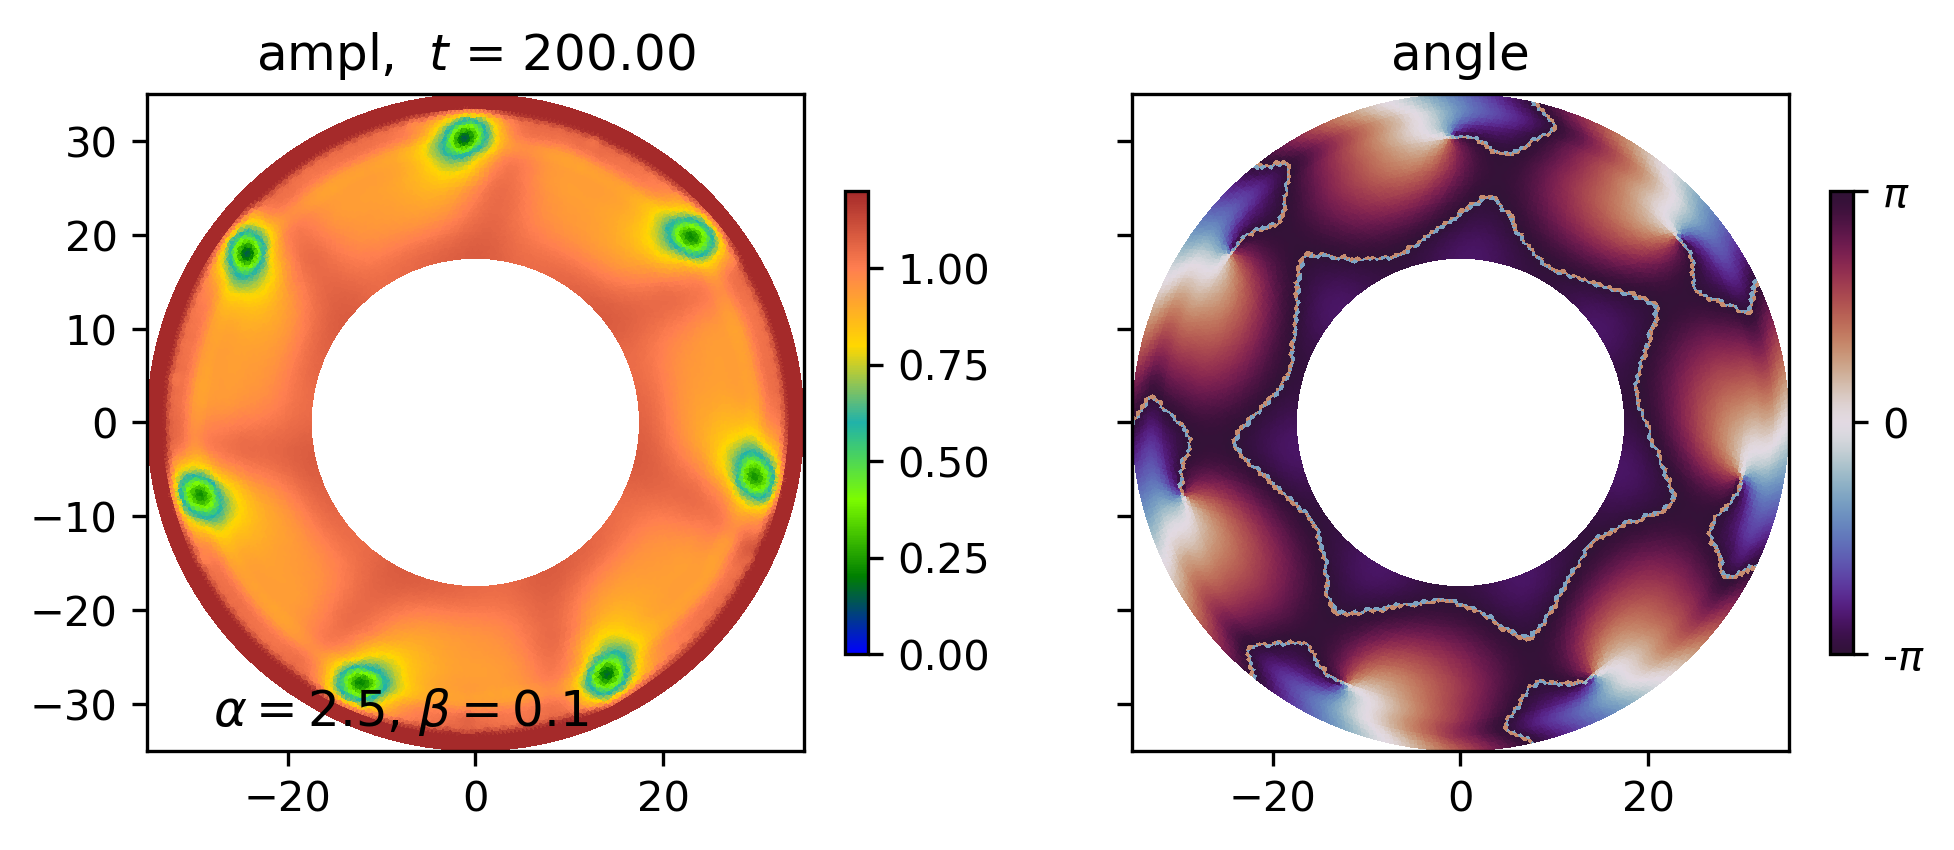

In [34]:
ofile = ofileroot + 'snap.png' 
cgle.disp(mesh,gfu,time,ofile=ofile,draw_mesh=False,subdivn=2,label=clabel,figsize=[7,3.5],cbar_shrink=0.45)
cgle.disp(mesh,gfu,time,ofile='',draw_mesh=False,subdivn=2,label=clabel,figsize=[7,3.5],cbar_shrink=0.45)